# Prueba 01 (Modelo HAHM)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import UpROOT.io as io
import UpROOT.config as conf
import UpROOT.physics.delphes as ph
import UpROOT.plotting.delphes as pt
import UpROOT.pipelines.delphes as pl
import UpROOT.fitting.delphes as fi
import UpROOT.delphes_root as dr

In [3]:
ANALYSIS = 'dp00'
cfg = conf.CONFIGURATIONS[ANALYSIS]
DATASET = cfg['raw_dataset']
PDATASET = cfg['flat_dataset']
PLOT_DATA = cfg['plot_data']
TARGET_MASS = None
MASS_RANGE = cfg['mass_range']
FIT_WINDOW = cfg['fit_window']

# Partícula a estudiar (código PDG/Status en Pythia/MadGraph)
PARTICLE_PID = 1023
PARTICLE_STATUS = 23
PARTICLE_LABEL = "Z'"
TAG = f'pid{PARTICLE_PID}_st{PARTICLE_STATUS}'

MIN_MUON_PT = 0.0
ETA_RANGE = (2.0, 5.0)

plot_options = {
    'save': True,
    'data': PLOT_DATA,
    'output_dir': None
}
particle_options = {**plot_options, 'label': PARTICLE_LABEL}

In [4]:
cut = '(PID == 1023) & (Status == 23)' # Código del fotón oscuro zp
BRANCHES = (
    'event_id',
    'source_entry',
    'object_index',
    'root_uid',
    'PID',
    'Status',
    'M1',
    'M2',
    'D1',
    'D2',
    'Mass',
    'E',
    'Px',
    'Py',
    'Pz',
    'P',
    'PT',
    'Eta',
    'Phi',
    'Rapidity',
    'T',
    'X',
    'Y',
    'Z',
)

In [5]:
df_events = io.load_dataframe(
    branches=None,
    dataset=PDATASET,
    tree_path='Events',
)
df_events.head()

Archivo: hahm00_pandas.root
Árbol seleccionado: Events
Total de eventos: 10,000 eventos


,source_file_id,event_id,source_entry,root_uid,event_number,ReadTime,ProcTime,ProcessID,MPI,event_weight,...,PDF2,n_EFlowTrack,n_Electron,n_Jet,n_MissingET,n_Muon,n_Particle,n_ScalarHT,n_Track,n_Weight
0,0,0,0,0,0,0.948643,0.010076,9999,-1,0.000002,...,0.0,38,0,0,1,0,1413,1,38,292
1,0,1,1,0,1,0.004811,0.003515,9999,-1,0.000002,...,0.0,56,0,0,1,0,1966,1,56,292
2,0,2,2,0,2,0.004540,0.003560,9999,-1,0.000002,...,0.0,54,0,0,1,0,2185,1,54,292
3,0,3,3,0,3,0.003410,0.002853,9999,-1,0.000002,...,0.0,44,0,0,1,0,1629,1,44,292
4,0,4,4,0,4,0.003760,0.002918,9999,-1,0.000002,...,0.0,54,0,1,1,0,1798,1,54,292


In [6]:
df_pid = io.load_dataframe(
    branches=('event_id', 'PID', 'Status'),
    dataset=PDATASET,
    tree_path='Particles'
)
display(
    df_pid.groupby(['PID', 'Status']).size()
    .rename('Particulas')
    .sort_values(ascending=False)
    .head(30)
)
del df_pid

Archivo: hahm00_pandas.root
Árbol seleccionado: Particles
Total de eventos: 12,253,776 eventos


PID    Status
 22    1         1825733
 21    51        1219534
       62         895273
 111   2          862333
 211   1          769562
-211   1          762218
 21    44         717231
       71         594136
       52         516124
       73         253529
       43         164084
       41         156688
       42         140560
       31         139998
       33         137686
       61         126770
 113   2          120498
 223   2          117978
 213   2          116909
-213   2          115196
 221   2           98485
 321   1           87526
-321   1           86150
 310   2           85347
 130   1           84774
 311   2           82880
-311   2           82078
 21    53          71608
 1023  44          68896
 2212  1           64013
Name: Particulas, dtype: int64

In [7]:
df_particle = io.load_dataframe(
    branches=BRANCHES,
    dataset=PDATASET,
    tree_path='Particles',
    cut=cut
)
df_particle.head(7)

Archivo: hahm00_pandas.root
Árbol seleccionado: Particles
Total de eventos: 19,960 eventos


,event_id,source_entry,object_index,root_uid,PID,Status,M1,M2,D1,D2,...,Pz,P,PT,Eta,Phi,Rapidity,T,X,Y,Z
3,0,0,3,4,1023,23,0,1,251,251,...,-117.641434,118.078827,10.153916,-3.144786,-1.842579,-2.359359,0.0,0.0,0.0,0.0
4,0,0,4,5,1023,23,0,1,252,252,...,-54.248085,55.190186,10.153916,-2.377501,1.299014,-1.616552,0.0,0.0,0.0,0.0
1416,1,1,3,4,1023,23,0,2,18,18,...,162.947510,167.983948,40.825459,2.092605,-0.908845,1.988631,0.0,0.0,0.0,0.0
1417,1,1,4,5,1023,23,0,2,19,19,...,625.195251,626.526794,40.825459,3.422970,2.232748,3.315672,0.0,0.0,0.0,0.0
3382,2,2,3,4,1023,23,0,2,38,38,...,-13.122395,18.298309,12.752680,-0.901726,2.804734,-0.528304,0.0,0.0,0.0,0.0
3383,2,2,4,5,1023,23,0,2,39,39,...,-35.634457,37.847660,12.752680,-1.751301,-0.336859,-1.196042,0.0,0.0,0.0,0.0
5567,3,3,3,4,1023,23,0,2,96,96,...,-43.413246,43.703804,5.031183,-2.851598,-0.849957,-1.489663,0.0,0.0,0.0,0.0


In [8]:
df_jet = io.load_dataframe(
    dataset=PDATASET,
    tree_path='Jets',
    branches=['event_id', 'object_index', 'PT', 'Eta', 'Phi', 'Mass', 'BTag']
)
df_jet.head()

Archivo: hahm00_pandas.root
Árbol seleccionado: Jets
Total de eventos: 3,007 eventos


,event_id,object_index,PT,Eta,Phi,Mass,BTag
0,4,0,51.844090,-3.343123,2.595220,11.057254,0
1,7,0,26.909838,-2.040212,1.024631,6.014088,0
2,13,0,29.511744,-1.565157,2.862662,3.570057,0
3,18,0,45.236713,3.438823,0.416201,6.336527,0
4,19,0,24.249216,2.616957,2.928521,3.681204,1


In [9]:
df_met = io.load_dataframe(
    dataset=PDATASET,
    tree_path='MissingET',
    branches=['event_id', 'MET', 'Eta', 'Phi']
)
df_met.head()

Archivo: hahm00_pandas.root
Árbol seleccionado: MissingET
Total de eventos: 10,000 eventos


,event_id,MET,Eta,Phi
0,0,13.338988,-4.072959,-1.004864
1,1,4.499871,-2.139929,-0.370714
2,2,9.756926,2.743701,0.661551
3,3,9.751801,-2.084493,2.022669
4,4,36.882423,3.660398,-0.303877


In [21]:
analysis = pl.prepare_particle_analysis(
    df_particle,
    pid=PARTICLE_PID,
    status=PARTICLE_STATUS,
    events=df_events,
    jets=df_jet,
    missing_et=df_met,
    require_two=True
)
truth_particles = analysis['truth_mediators']
truth_pairs = analysis['truth_pairs']
event_observables = analysis['event_observables']
summary = analysis['summary']
truth_pairs.head()

,event_id,n_truth_particles,truth1_index,truth1_pid,truth1_status,truth1_mass,truth1_x,truth1_y,truth1_z,truth1_t,...,truth_pair_px,truth_pair_py,truth_pair_pz,truth_pair_mass,truth_pair_pt,truth_pair_eta,truth_pair_phi,truth_pair_rapidity,truth_pair_delta_phi,truth_pair_delta_r
0,0,2,3,1023,23,20.0,0.0,0.0,0.0,0.0,...,0.0,0.0,-171.889519,47.989604,0.0,NaN,0.0,-1.987955,-3.141593,3.233934
1,1,2,3,1023,23,20.0,0.0,0.0,0.0,0.0,...,0.0,0.0,788.142761,111.682282,0.0,NaN,0.0,2.652151,-3.141593,3.411667
2,2,2,3,1023,23,20.0,0.0,0.0,0.0,0.0,...,0.0,0.0,-48.756851,50.108349,0.0,NaN,0.0,-0.862173,-3.141593,3.254440
3,3,2,3,1023,23,20.0,0.0,0.0,0.0,0.0,...,0.0,0.0,-1011.726662,99.378111,0.0,NaN,0.0,-3.016032,3.141593,4.414594
4,4,2,3,1023,23,20.0,0.0,0.0,0.0,0.0,...,0.0,0.0,-2516.491699,62.597872,0.0,NaN,0.0,-4.387192,-3.141593,3.395785


In [34]:
truth_particles.head()

,event_id,source_entry,object_index,root_uid,PID,Status,M1,M2,D1,D2,...,Pz,P,PT,Eta,Phi,Rapidity,T,X,Y,Z
3,0,0,3,4,1023,23,0,1,251,251,...,-117.641434,118.078827,10.153916,-3.144786,-1.842579,-2.359359,0.0,0.0,0.0,0.0
4,0,0,4,5,1023,23,0,1,252,252,...,-54.248085,55.190186,10.153916,-2.377501,1.299014,-1.616552,0.0,0.0,0.0,0.0
1416,1,1,3,4,1023,23,0,2,18,18,...,162.947510,167.983948,40.825459,2.092605,-0.908845,1.988631,0.0,0.0,0.0,0.0
1417,1,1,4,5,1023,23,0,2,19,19,...,625.195251,626.526794,40.825459,3.422970,2.232748,3.315672,0.0,0.0,0.0,0.0
3382,2,2,3,4,1023,23,0,2,38,38,...,-13.122395,18.298309,12.752680,-0.901726,2.804734,-0.528304,0.0,0.0,0.0,0.0


In [18]:
display(pd.Series(summary, name='resumen'))

pid                                               [1023]
status_filter                                         23
n_total_events                                     10000
n_mediator_rows_all_statuses                       19960
n_mediator_rows_selected                           19960
n_events_with_mediator                              9980
n_events_with_exactly_two                           9980
fraction_total_events_with_mediator                0.998
fraction_selected_events_with_exactly_two            1.0
status_counts                                {23: 19960}
multiplicity_counts                            {2: 9980}
mass_mean_gev                                       20.0
mass_std_gev                                         0.0
mass_median_gev                                     20.0
n_mediators_with_daughter_indices                  19960
fraction_mediators_with_daughter_indices             1.0
n_truth_pairs                                       9980
n_events_with_missing_et       

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\event_multiplicities.png.


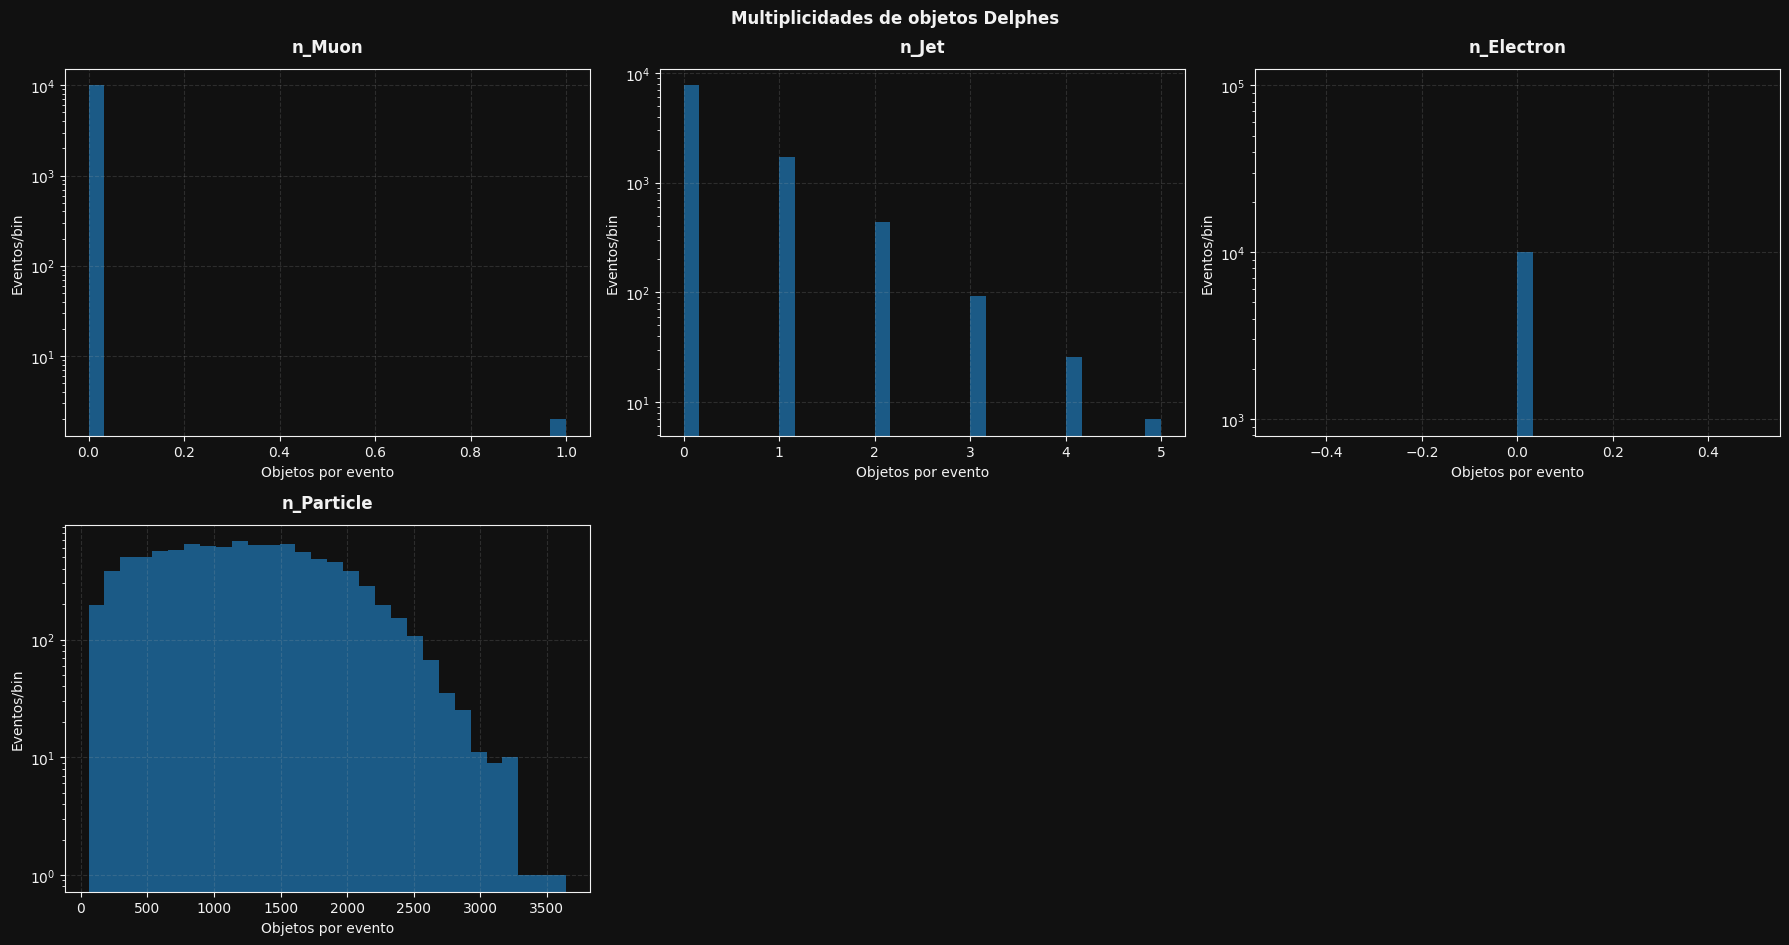

(<Figure size 1800x960 with 6 Axes>,
 array([[<Axes: title={'center': 'n_Muon'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Jet'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Electron'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>],
        [<Axes: title={'center': 'n_Particle'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: >, <Axes: >]], dtype=object))

In [22]:
pt.plot_event_multiplicities(
    df_events,
    filename='event_multiplicities',
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\particle_kinematics_pid1023_st23.png.


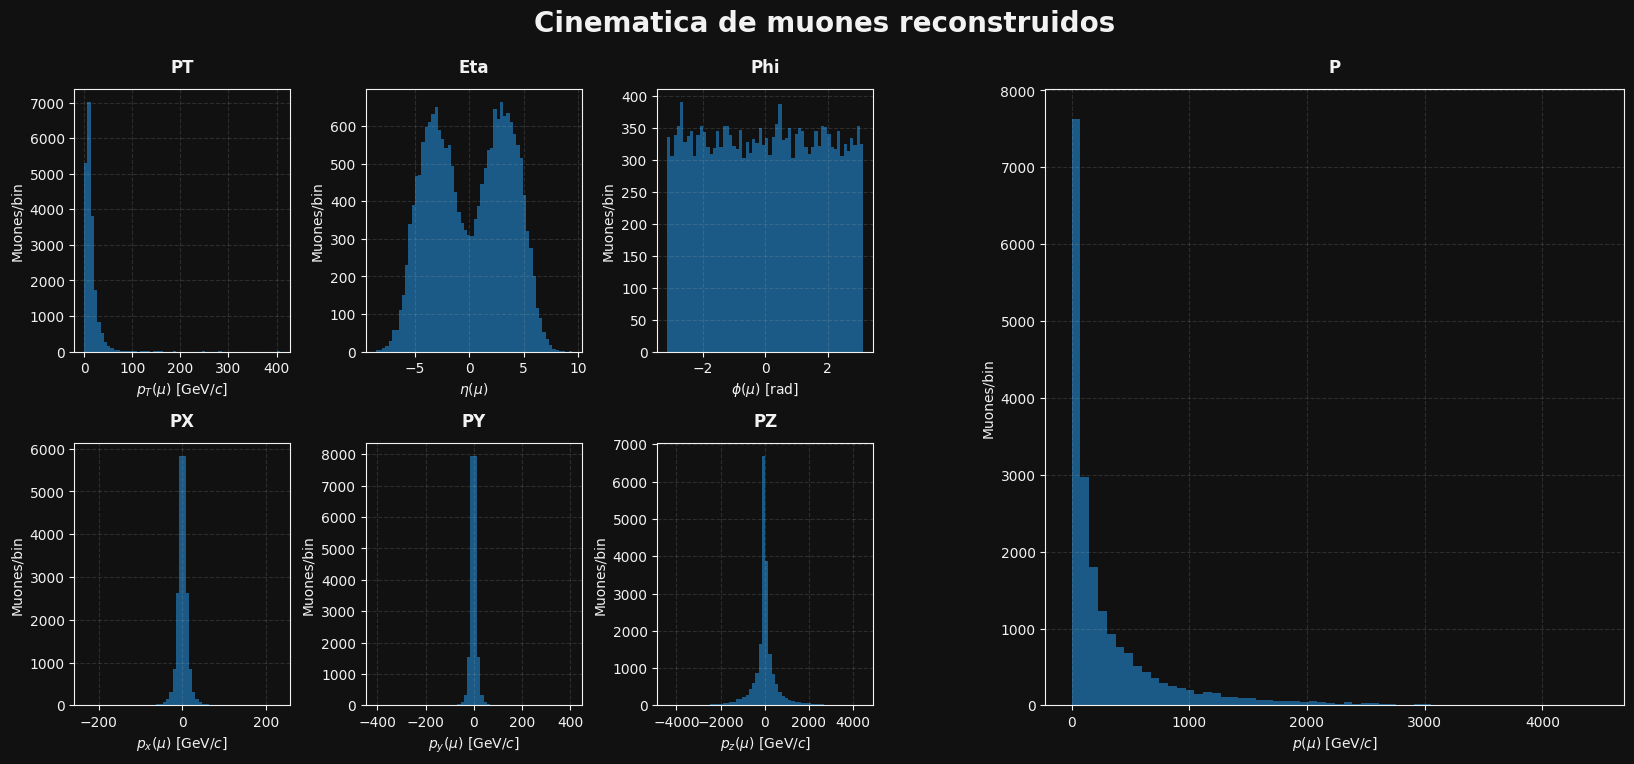

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel='$p_T(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel='$\\eta(\\mu)$', ylabel='Muones/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel='$\\phi(\\mu)$ [rad]', ylabel='Muones/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel='$p_x(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel='$p_y(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel='$p_z(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel='$p(\\mu)$ [GeV/$c$]', ylabel='Muones/bin'>})

In [23]:
pt.plot_muon_kinematics(
    df_particle, 
    bins=60, 
    filename=f"particle_kinematics_{TAG}",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\zp_kinematics.png.


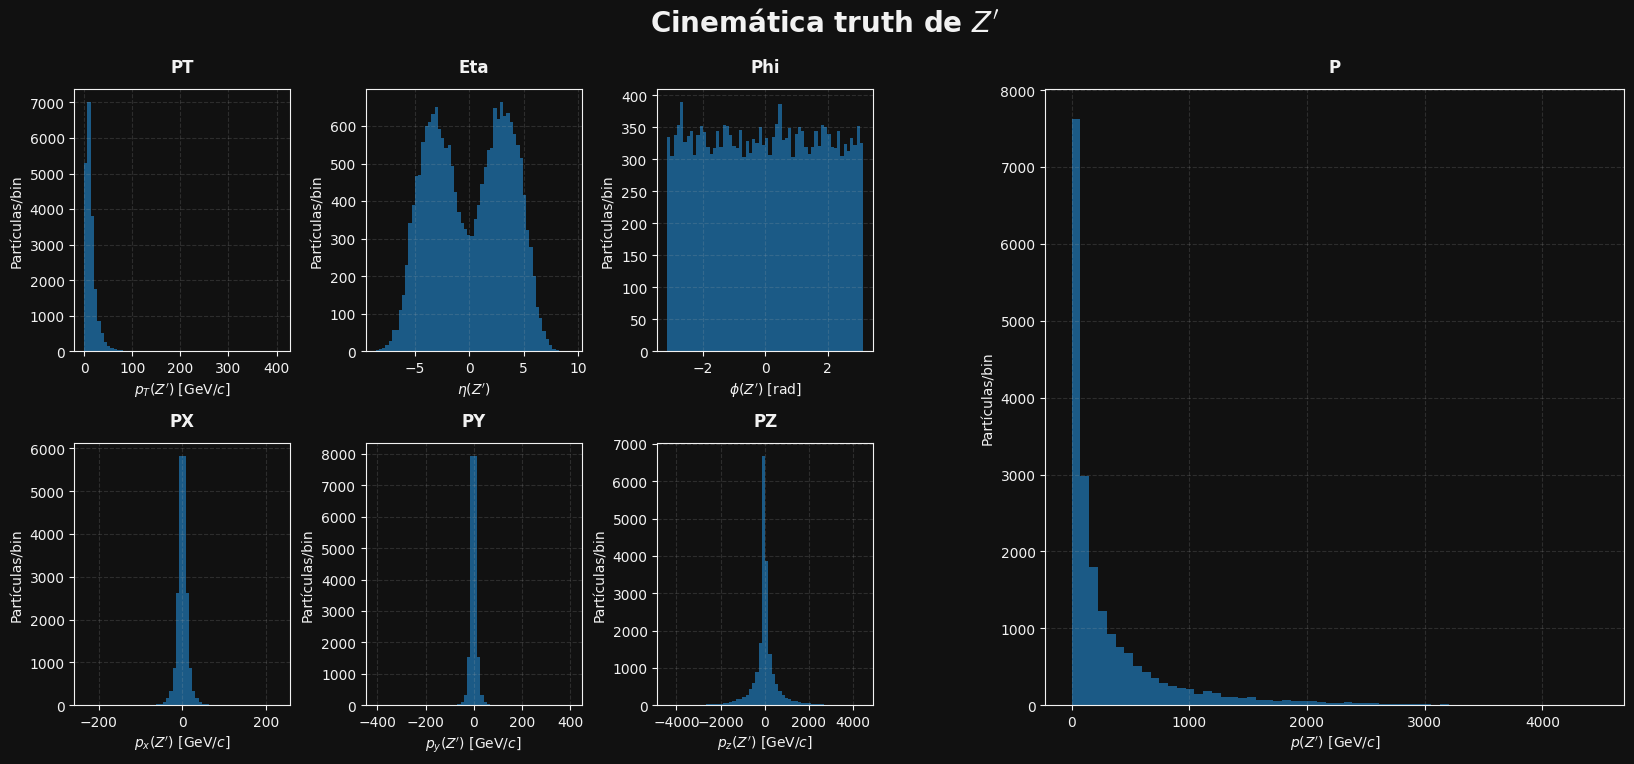

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel="$p_T(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel="$\\eta(Z')$", ylabel='Partículas/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel="$\\phi(Z')$ [rad]", ylabel='Partículas/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel="$p_x(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel="$p_y(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel="$p_z(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel="$p(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>})

In [26]:
pt.plot_particle_kinematics(
    truth_particles, 
    bins=60, 
    filename="zp_kinematics",
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\particle_kinematics_TAG_split.png.


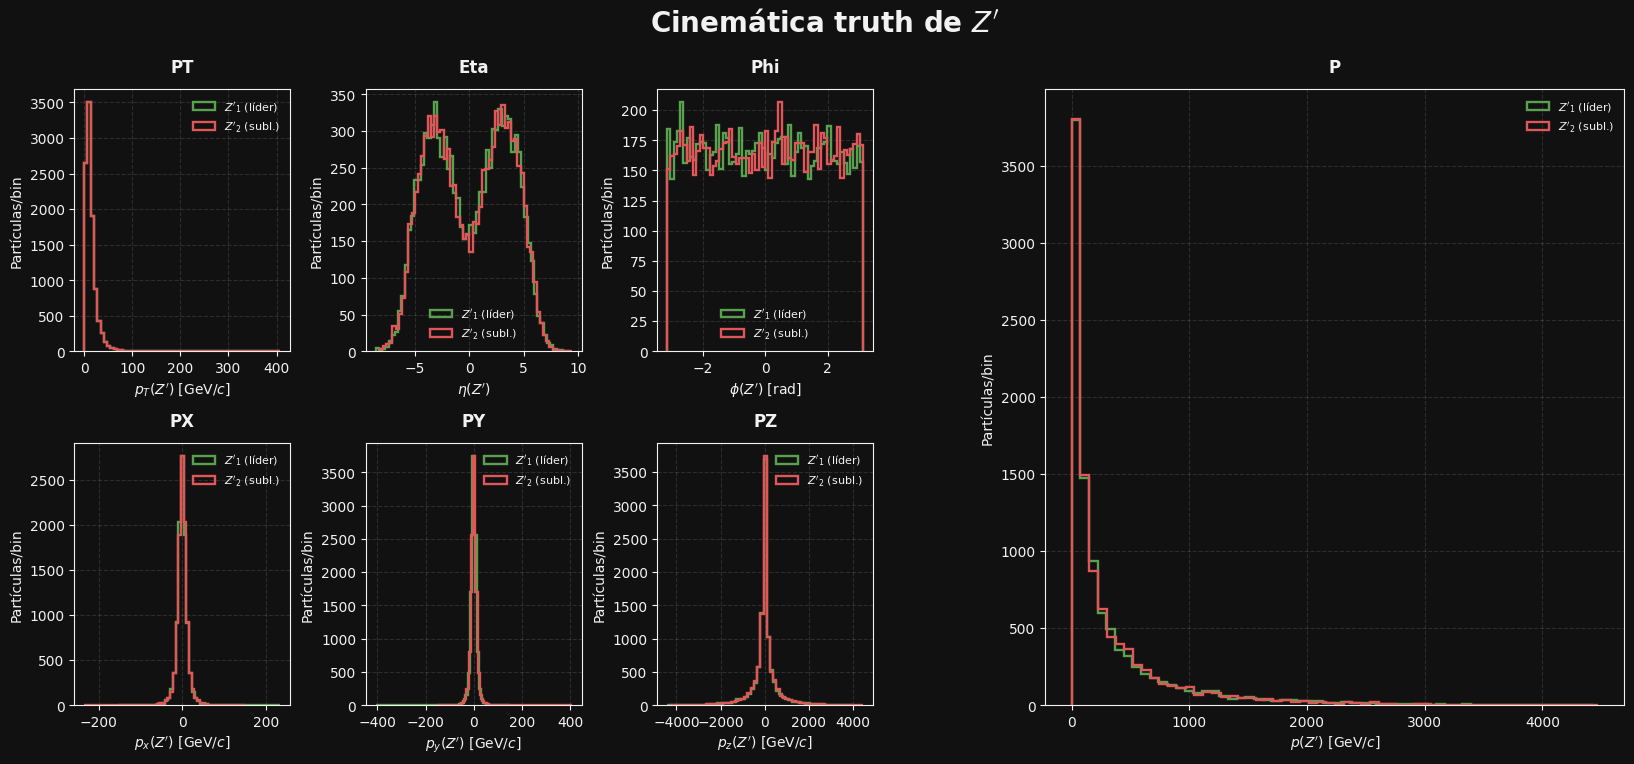

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel="$p_T(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel="$\\eta(Z')$", ylabel='Partículas/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel="$\\phi(Z')$ [rad]", ylabel='Partículas/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel="$p_x(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel="$p_y(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel="$p_z(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel="$p(Z')$ [GeV/$c$]", ylabel='Partículas/bin'>})

In [27]:
pt.plot_particle_kinematics(
    truth_particles, 
    bins=60,
    split_rank=True,
    filename="particle_kinematics_{TAG}_split",
    **plot_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\particle_mass_pid1023_st23.png.


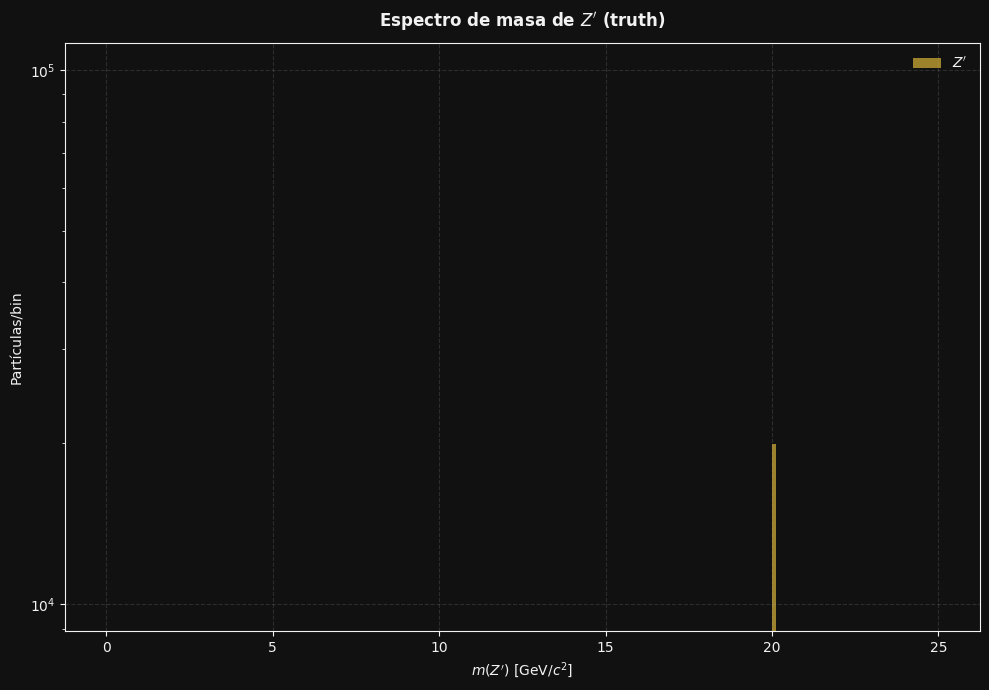

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': "Espectro de masa de $Z'$ (truth)"}, xlabel="$m(Z')$ [GeV/$c^2$]", ylabel='Partículas/bin'>)

In [37]:
pt.plot_particle_mass(
    truth_particles,
    bins=200,
    mass_range=(0.0, 25.0),
    log_x=False,
    log_y=True,
    filename=f'particle_mass_{TAG}',
    **plot_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\particle_pair_mass_pid1023_st23.png.


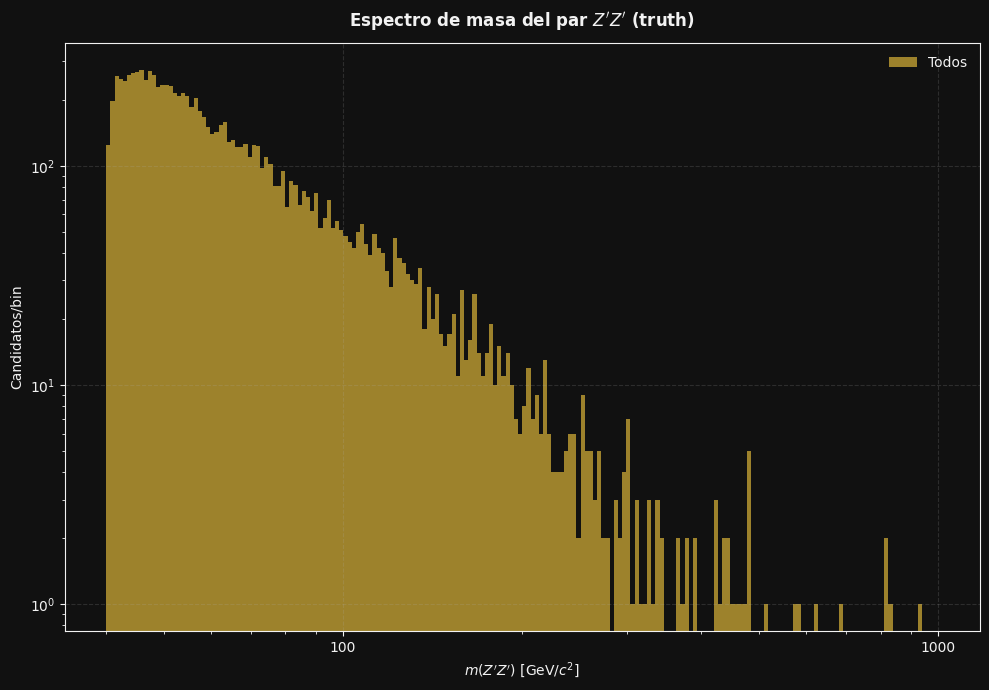

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': "Espectro de masa del par $Z'Z'$ (truth)"}, xlabel="$m(Z'Z')$ [GeV/$c^2$]", ylabel='Candidatos/bin'>)

In [29]:
pt.plot_particle_pair_mass(
    truth_pairs,
    bins=200,
    log_x=True,
    log_y=True,
    mass_range=(0.0, 1000.0),
    filename=f'particle_pair_mass_{TAG}',
    **plot_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\jet_kinematics_pid1023_st23.png.


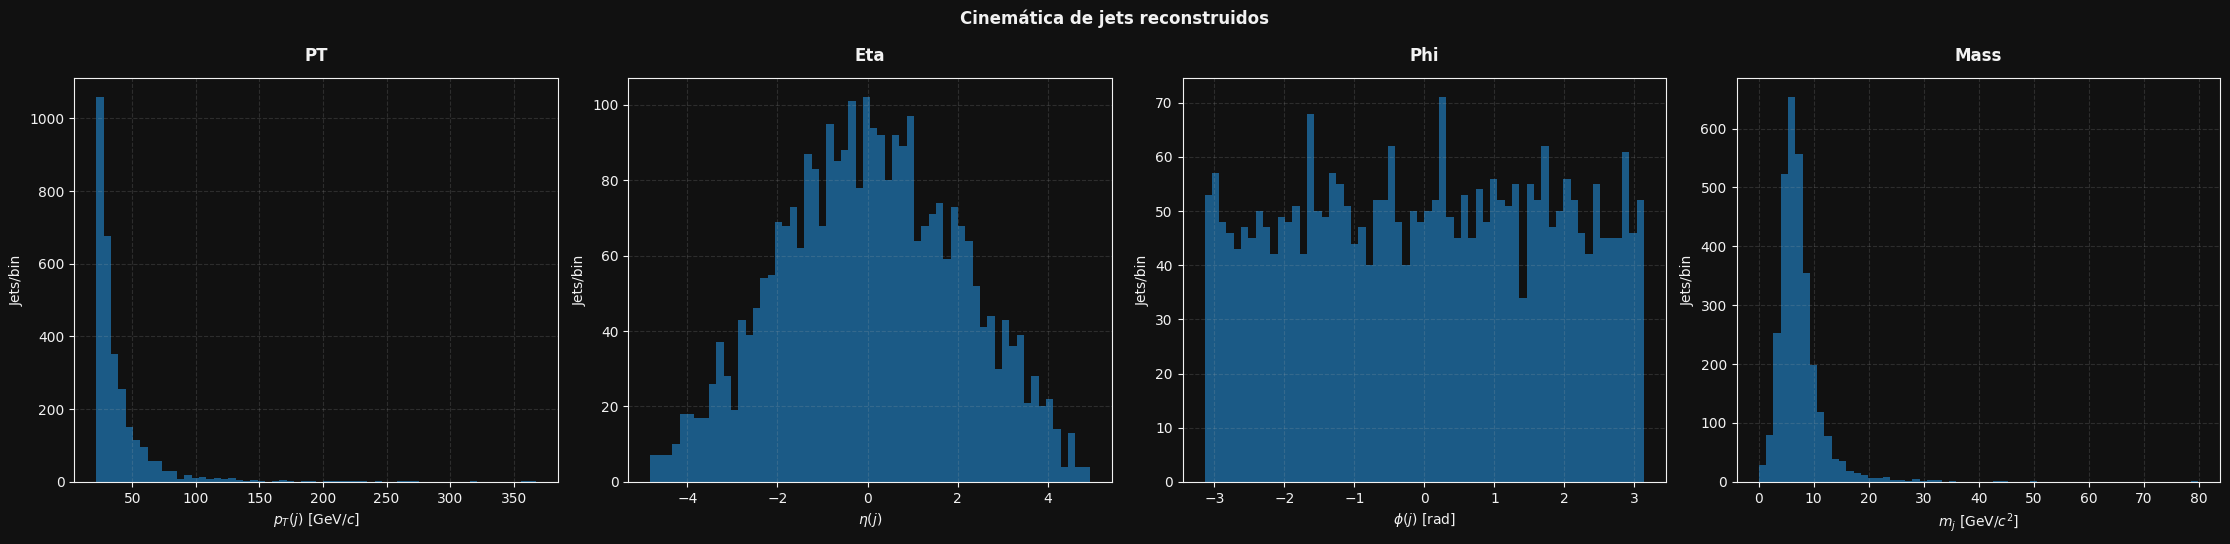

(<Figure size 2240x550 with 4 Axes>,
 array([[<Axes: title={'center': 'PT'}, xlabel='$p_T(j)$ [GeV/$c$]', ylabel='Jets/bin'>,
         <Axes: title={'center': 'Eta'}, xlabel='$\\eta(j)$', ylabel='Jets/bin'>,
         <Axes: title={'center': 'Phi'}, xlabel='$\\phi(j)$ [rad]', ylabel='Jets/bin'>,
         <Axes: title={'center': 'Mass'}, xlabel='$m_j$ [GeV/$c^2$]', ylabel='Jets/bin'>]],
       dtype=object))

In [30]:
pt.plot_jet_kinematics(
    df_jet,
    bins=60,
    filename=f'jet_kinematics_{TAG}',
    **plot_options
)